# 04 Hazard models

All of the hazard models, in one notebook, following the plan (`02-plan.ipynb`):

| Model | What changes | Why |
|---|---|---|
| Logit hazard | nothing: the core model | Logistic regression is the baseline (lecture 01.2); standard in credit (Shumway, 2001) |
| Cloglog hazard | the link | The grouped-time Cox model (Prentice & Gloeckler, 1978); $e^{\beta}$ are hazard ratios |
| Logit hazard, L1 / L2 | a penalty, chosen by cross-validation | Lectures 02.2 and 3.1.P |
| Cox, time-varying covariates | continuous time | The literature standard (Cox, 1972), on the same rows |

Plus a **one-row-per-customer logit on the October rows only**, the fair test of whether the extra months help.

Everything is chosen on the **training** customers by 10-fold cross-validation with whole customers left out
(lecture 02.2). The validation set is then a single honest check, and the test set is used once at the end.

## Where the code comes from

| Piece | Source | Reused how |
|---|---|---|
| Binomial GLM, logit / cloglog link, customer-clustered standard errors, AIC / BIC | statsmodels: [GLM](https://www.statsmodels.org/stable/glm.html), [`GLM.fit`](https://www.statsmodels.org/stable/generated/statsmodels.genmod.generalized_linear_model.GLM.fit.html) | Library calls as documented |
| Penalised logistic regression | scikit-learn: [`LogisticRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) | Library call; `l1_ratio` picks L1 / L2 |
| Grouped cross-validation | scikit-learn: [`GroupKFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html) | Library call; the loop around it is my own |
| Cox with time-varying covariates | lifelines: [*Time varying survival regression*](https://lifelines.readthedocs.io/en/stable/Time%20varying%20survival%20regression.html) (Davidson-Pilon, 2019) | Their data layout and call; the monthly prediction is my own |
| ROC, PR and calibration curves | scikit-learn: [`roc_curve`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html), [`precision_recall_curve`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_curve.html), [`calibration_curve`](https://scikit-learn.org/stable/modules/generated/sklearn.calibration.calibration_curve.html) | Library calls |
| Paired bootstrap | SciPy: [`scipy.stats.bootstrap`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html) | Library call |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from lifelines import CoxTimeVaryingFitter
from scipy.stats import bootstrap
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, log_loss, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GroupKFold

import prep

wide = prep.load_split()                  # train and validation; see 03-data.ipynb
pm = prep.person_months(wide)
train, val = pm["train"], pm["validation"]
{part: df.shape for part, df in pm.items()}

{'train': (89985, 21), 'validation': (29995, 21)}

## 1. The models

Every model predicts the monthly hazard $h(t \mid x)$ from last month's covariates $x_{t-1}$:

$$\text{link}\big(h(t \mid x)\big) = \alpha_t + \beta^\top x_{t-1}$$

* **logit**: $\log\frac{h}{1-h}$. A logistic regression on the person-month rows (lecture 01.2), fitted by maximum
  likelihood; $\beta$ are log odds ratios of the monthly hazard.
* **cloglog**: $\log(-\log(1-h))$. If defaults happen in continuous time but are only seen monthly, this is exact,
  and $e^{\beta}$ are hazard ratios.
* **penalised**: the logit, minimising the log loss plus $\frac1C$ times an L1 ($\sum|\beta_j|$) or L2
  ($\sum\beta_j^2$) penalty.
* **Cox**: $h(t \mid x) = h_0(t)\,e^{\beta^\top x_{t-1}}$, fitted by partial likelihood; the baseline $h_0$ replaces
  the month dummies.

$\alpha_t$ is one intercept per month (the month dummies), so the baseline hazard is fully flexible. Why the
likelihood is an ordinary logistic regression: the chance a customer's history happened is the product, over their
months, of $h$ (event) or $1-h$ (no event), which is exactly a Bernoulli likelihood over the rows (Allison, 1982).

In [2]:
LINKS = {"logit": sm.families.links.Logit(), "cloglog": sm.families.links.CLogLog()}


def fit_glm(data, link="logit", cols=None):
    """Discrete-time hazard: a binomial GLM on the person-month rows.

    Standard errors are clustered by customer (rows of one customer are not
    independent); the coefficients are the same either way.
    """
    cols = cols or prep.features(data)
    model = sm.GLM(data["event"], sm.add_constant(data[cols]), family=sm.families.Binomial(link=LINKS[link]))
    return model.fit(cov_type="cluster", cov_kwds={"groups": data.index.to_numpy()})


def fit_penalised(data, penalty="l2", C=1.0):
    """The logit hazard with a lasso (l1) or ridge (l2) penalty. Small C = strong penalty."""
    model = LogisticRegression(C=C, l1_ratio=1.0 if penalty == "l1" else 0.0,
                               solver="liblinear" if penalty == "l1" else "lbfgs", max_iter=2000)
    return model.fit(data[prep.features(data)], data["event"])


def fit_cox(data):
    """Cox model with time-varying covariates: each row is the interval (t-1, t].

    A small ridge penalty and a shorter Newton step stop it diverging (the default step
    gives coefficients near 45: the status dummies are nearly separable in some months).
    Ties, thousands of events per month, are handled by Efron's method.
    """
    cols = prep.features(data, months=False)
    df = data[cols].assign(id=data.index, start=data["t"] - 1, stop=data["t"],
                           event=data["event"].astype(bool)).reset_index(drop=True)
    model = CoxTimeVaryingFitter(penalizer=0.01)
    return model.fit(df, id_col="id", event_col="event", start_col="start", stop_col="stop",
                     fit_options={"step_size": 0.3}, show_progress=False)


def fit_october_only(data):
    """The ordinary one-row-per-customer logit: the October rows, no month dummies."""
    rows = prep.october(data)
    return fit_glm(rows, cols=prep.features(rows, months=False))


def predict(model, rows):
    """The hazard for each row. Cox has no predict for time-varying fits, so its monthly
    hazard is built from the baseline: h = 1 - exp(-[H0(t) - H0(t-1)] * exp((x - mean)'beta))."""
    if isinstance(model, CoxTimeVaryingFitter):
        H0 = model.baseline_cumulative_hazard_.iloc[:, 0]
        h0 = (H0.reindex(rows["t"]).to_numpy() - H0.reindex(rows["t"] - 1).fillna(0).to_numpy())
        p = 1 - np.exp(-h0 * model.predict_partial_hazard(rows[model.params_.index]).to_numpy())
    elif isinstance(model, LogisticRegression):
        p = model.predict_proba(rows[model.feature_names_in_])[:, 1]
    else:
        cols = [c for c in model.model.exog_names if c != "const"]
        p = model.predict(sm.add_constant(rows[cols], has_constant="add"))
    return pd.Series(np.asarray(p), index=rows.index, name="probability")


def predict_october(model, data):
    """P(default in October): the hazard of each customer's October row."""
    return predict(model, prep.october(data))


def score(y, p):
    """Ranking (AUC, average precision = area under the PR curve) and probabilities (Brier, log loss)."""
    return {"AUC": roc_auc_score(y, p), "avg precision": average_precision_score(y, p),
            "Brier": brier_score_loss(y, p), "log loss": log_loss(y, p)}


MODELS = {
    "logit hazard": lambda d: fit_glm(d, "logit"),
    "cloglog hazard": lambda d: fit_glm(d, "cloglog"),
    "logit hazard, L1": lambda d: fit_penalised(d, "l1", C=1.0),
    "logit hazard, L2": lambda d: fit_penalised(d, "l2", C=1.0),
    "Cox, time-varying": fit_cox,
    "logit, October rows only": fit_october_only,
}

## 2. Cross-validation with whole customers left out

Lecture 02.2: with correlated rows, redefine the data point. Here the unit is the **customer**: `GroupKFold` puts all
five of a customer's rows in the same fold, so no customer is in both the fitting and the scoring part. Each fold is
scored on its left-out customers' **October** rows, the number the group compares.

In [3]:
FOLDS = list(GroupKFold(n_splits=10, shuffle=True, random_state=prep.SEED).split(train, groups=train.index))


def cross_validate(fit, data=train, folds=FOLDS):
    """Fit on 9 folds of customers, score the 10th on October; one row of scores per fold."""
    rows = []
    for fit_idx, score_idx in folds:
        model = fit(data.iloc[fit_idx])
        held_out = data.iloc[score_idx]
        rows.append(score(prep.october(held_out)["event"], predict_october(model, held_out)))
    return pd.DataFrame(rows)


cv_results = {name: cross_validate(fit) for name, fit in MODELS.items()}
cv_table = pd.DataFrame({name: cv.mean() for name, cv in cv_results.items()}).T
cv_table["AUC sd"] = [cv["AUC"].std() for cv in cv_results.values()]
cv_table.round(4)

,AUC,avg precision,Brier,log loss,AUC sd
logit hazard,0.7330,0.5066,0.1424,0.4582,0.0125
cloglog hazard,0.7303,0.5063,0.1436,0.4652,0.0121
"logit hazard, L1",0.7330,0.5067,0.1423,0.4582,0.0125
"logit hazard, L2",0.7329,0.5064,0.1424,0.4582,0.0126
"Cox, time-varying",0.7309,0.5049,0.1450,0.4722,0.0124
"logit, October rows only",0.7469,0.5161,0.1394,0.4456,0.0105


## 3. Model selection: bigger models always fit better

Portfolio 2.1.P: in nested models, the bigger one always has the higher training likelihood, so training fit cannot
choose between them. AIC, BIC and cross-validation all charge for extra parameters. Four nested logit hazards:

* BIC needs a sample size $n$, and here it is ambiguous: 90,000 **rows** or 18,000 **customers**? The rows are not
  independent, so the customer count is arguably the honest one. Both are shown.
* AIC and BIC also assume independent rows; cross-validation by customer does not.

In [4]:
f = prep.features(train)
NESTED = {
    "months only": [c for c in f if c.startswith("t_")],
    "+ last month's status": [c for c in f if c.startswith(("t_", "status_lag"))],
    "+ utilisation, payment ratio": [c for c in f if c.startswith(("t_", "status_lag", "util", "payratio"))],
    "+ limit, age, demographics (full)": f,
}
n_rows, n_customers = len(train), train.index.nunique()
rows = []
for name, cols in NESTED.items():
    res = fit_glm(train, cols=cols)
    k = len(res.params)
    cv = cross_validate(lambda d, cols=cols: fit_glm(d, cols=cols))
    rows.append({"model": name, "parameters": k, "log-likelihood (train)": res.llf,
                 "AIC": res.aic, "BIC (n = rows)": -2 * res.llf + k * np.log(n_rows),
                 "BIC (n = customers)": -2 * res.llf + k * np.log(n_customers),
                 "CV log loss": cv["log loss"].mean(), "CV AUC": cv["AUC"].mean()})
selection = pd.DataFrame(rows).set_index("model")
selection.round(4)

,parameters,log-likelihood (train),AIC,BIC (n = rows),BIC (n = customers),CV log loss,CV AUC
model,,,,,,,
months only,5,-36962.4482,73934.8965,73981.9335,73973.8863,0.5285,0.5000
+ last month's status,10,-26443.9032,52907.8064,53001.8804,52985.7860,0.4667,0.6805
"+ utilisation, payment ratio",12,-26107.4455,52238.8910,52351.7798,52332.4666,0.4652,0.7034
"+ limit, age, demographics (full)",20,-25783.8990,51607.7981,51795.9460,51763.7573,0.4582,0.7330


## 4. Choosing the penalty by cross-validation

Lectures 02.2 and 3.1.P: choose the penalty strength $C$ by cross-validation, not on one held-out set. The choice is
made on **log loss**, a proper scoring rule (Portfolio 1.2.P), with AUC shown alongside.

In [5]:
GRID = np.logspace(-3, 1, 5)
rows = []
for pen in ("l1", "l2"):
    for C in GRID:
        cv = cross_validate(lambda d, pen=pen, C=C: fit_penalised(d, pen, C))
        rows.append({"penalty": pen, "C": C, "AUC mean": cv["AUC"].mean(), "AUC sd": cv["AUC"].std(),
                     "log loss mean": cv["log loss"].mean()})
tuning = pd.DataFrame(rows)
best_C = {pen: tuning.loc[tuning.loc[tuning["penalty"] == pen, "log loss mean"].idxmin(), "C"] for pen in ("l1", "l2")}
print("C chosen by CV log loss:", best_C)
tuning.round(4)

C chosen by CV log loss: {'l1': np.float64(0.01), 'l2': np.float64(0.01)}


,penalty,C,AUC mean,AUC sd,log loss mean
0,l1,0.001,0.7209,0.0136,0.4697
1,l1,0.010,0.7298,0.0134,0.4560
2,l1,0.100,0.7330,0.0126,0.4578
3,l1,1.000,0.7330,0.0125,0.4582
4,l1,10.000,0.7330,0.0125,0.4582
5,l2,0.001,0.7217,0.0147,0.4595
6,l2,0.010,0.7324,0.0129,0.4553
7,l2,0.100,0.7332,0.0125,0.4576
8,l2,1.000,0.7329,0.0126,0.4582
9,l2,10.000,0.7328,0.0126,0.4583


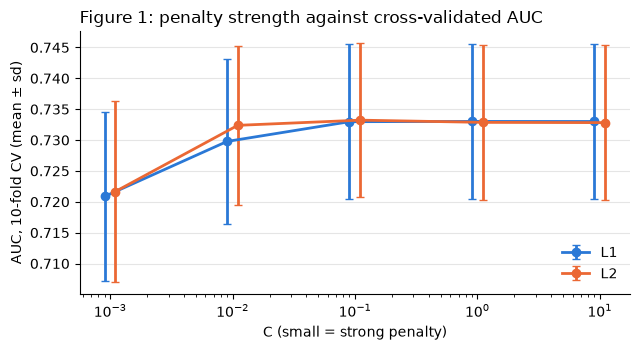

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for pen, colour, nudge in (("l1", "#2a78d6", 0.9), ("l2", "#eb6834", 1.1)):   # nudge: so the error bars don't overlap
    sub = tuning[tuning["penalty"] == pen]
    ax.errorbar(sub["C"] * nudge, sub["AUC mean"], yerr=sub["AUC sd"], marker="o", markersize=6, linewidth=2,
                capsize=3, color=colour, label=pen.upper())
ax.set_xscale("log")
ax.set_xlabel("C (small = strong penalty)")
ax.set_ylabel("AUC, 10-fold CV (mean ± sd)")
ax.set_title("Figure 1: penalty strength against cross-validated AUC", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 5. The honest check: the validation customers

Each model, fitted once on all training customers (the penalised ones at the cross-validated C), scored on the
validation customers' October row. Nothing was chosen on these customers.

In [7]:
MODELS["logit hazard, L1"] = lambda d: fit_penalised(d, "l1", C=best_C["l1"])
MODELS["logit hazard, L2"] = lambda d: fit_penalised(d, "l2", C=best_C["l2"])
fitted = {name: fit(train) for name, fit in MODELS.items()}
y_val = prep.october(val)["event"]
p_val = {name: predict_october(m, val) for name, m in fitted.items()}
pd.DataFrame({name: score(y_val, p) for name, p in p_val.items()}).T.round(4)

,AUC,avg precision,Brier,log loss
logit hazard,0.7438,0.5297,0.1380,0.4460
cloglog hazard,0.7442,0.5323,0.1385,0.4502
"logit hazard, L1",0.7368,0.5212,0.1382,0.4460
"logit hazard, L2",0.7394,0.5236,0.1380,0.4457
"Cox, time-varying",0.7447,0.5307,0.1407,0.4597
"logit, October rows only",0.7503,0.5360,0.1365,0.4389


ROC and precision-recall curves (lecture 01.2). The hazard variants lie almost on top of each other, so three are
drawn: the logit hazard, Cox and the October-only logit.

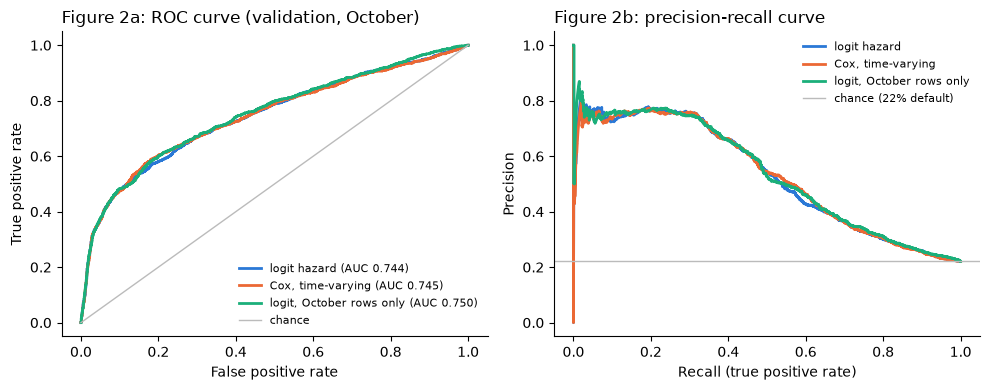

In [8]:
SHOW = {"logit hazard": "#2a78d6", "Cox, time-varying": "#eb6834", "logit, October rows only": "#1baf7a"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
for name, colour in SHOW.items():
    fpr, tpr, _ = roc_curve(y_val, p_val[name])
    precision, recall, _ = precision_recall_curve(y_val, p_val[name])
    ax1.plot(fpr, tpr, linewidth=2, color=colour, label=f"{name} (AUC {roc_auc_score(y_val, p_val[name]):.3f})")
    ax2.plot(recall, precision, linewidth=2, color=colour, label=name)
ax1.plot([0, 1], [0, 1], color="#bbbbbb", linewidth=1, label="chance")
ax2.axhline(y_val.mean(), color="#bbbbbb", linewidth=1, label=f"chance ({y_val.mean():.0%} default)")
ax1.set(xlabel="False positive rate", ylabel="True positive rate")
ax2.set(xlabel="Recall (true positive rate)", ylabel="Precision")
ax1.set_title("Figure 2a: ROC curve (validation, October)", loc="left")
ax2.set_title("Figure 2b: precision-recall curve", loc="left")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

**Is the difference real?** A paired bootstrap over validation customers (lecture 05.2: resample the exchangeable
unit, here customers, keeping each customer's label and both predictions together) for the AUC difference between
the October-only logit and the logit hazard.

In [9]:
def auc_difference(y, p_a, p_b):
    return roc_auc_score(y, p_a) - roc_auc_score(y, p_b)


a, b = "logit, October rows only", "logit hazard"
boot = bootstrap((y_val.to_numpy(), p_val[a].to_numpy(), p_val[b].to_numpy()), auc_difference, paired=True,
                 vectorized=False, n_resamples=1000, method="percentile", random_state=prep.SEED)
print(f"AUC({a}) - AUC({b}) = {auc_difference(y_val, p_val[a], p_val[b]):.4f}, "
      f"95% interval [{boot.confidence_interval.low:.4f}, {boot.confidence_interval.high:.4f}]")

AUC(logit, October rows only) - AUC(logit hazard) = 0.0065, 95% interval [-0.0021, 0.0147]


## 6. Logit against cloglog, and the clustered standard errors

Near-identical coefficients are expected when monthly hazards are small. The last column checks how much larger the
customer-clustered standard errors are than the naive ones (which assume independent rows).

In [10]:
logit, cloglog = fitted["logit hazard"], fitted["cloglog hazard"]
naive = sm.GLM(logit.model.endog, logit.model.exog, family=logit.model.family).fit()
pd.DataFrame({"logit": logit.params, "cloglog": cloglog.params, "cloglog hazard ratio": np.exp(cloglog.params),
              "clustered / naive SE": logit.bse / naive.bse}).round(3)

,logit,cloglog,cloglog hazard ratio,clustered / naive SE
const,-2.268,-2.270,0.103,0.955
util_lag,0.065,0.034,1.035,0.997
payratio_lag,-0.315,-0.283,0.753,1.032
log_limit,-0.294,-0.200,0.819,0.945
age,0.038,0.024,1.025,0.943
status_lag_-2,-0.671,-0.707,0.493,0.971
status_lag_0,-0.542,-0.432,0.649,1.033
status_lag_1,0.788,0.907,2.477,1.044
status_lag_2,2.656,2.125,8.370,1.042
status_lag_3,3.061,2.292,9.894,1.030


## 7. Calibration

Portfolio 1.2.P asks whether a proper score is the same as calibration. Two checks on the validation customers:
**by month**, the mean predicted hazard against the actual event rate (the actual-vs-expected idea of Botha &
Muller, 2025, applied to our set-up); **in October**, `calibration_curve` with ten equal-sized bins.

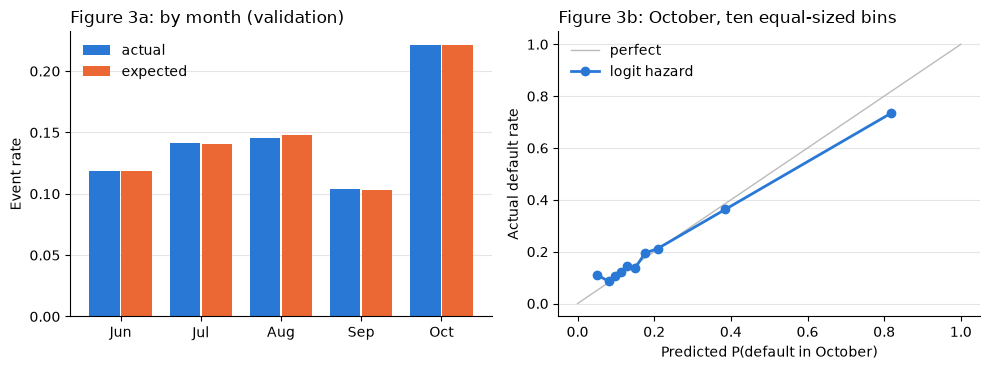

,predicted,actual
0,0.050,0.112
1,0.082,0.085
2,0.098,0.107
3,0.113,0.122
4,0.130,0.143
5,0.151,0.139
6,0.176,0.195
7,0.209,0.212
8,0.386,0.363
9,0.819,0.735


In [11]:
p_all = predict(logit, val)
term = pd.DataFrame({"actual": val.groupby("t")["event"].mean(), "expected": p_all.groupby(val["t"]).mean()})
actual_rate, predicted_rate = calibration_curve(y_val, p_val["logit hazard"], n_bins=10, strategy="quantile")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
x = np.arange(len(term))
ax1.bar(x - 0.2, term["actual"], width=0.38, color="#2a78d6", label="actual")
ax1.bar(x + 0.2, term["expected"], width=0.38, color="#eb6834", label="expected")
ax1.set_xticks(x, ["Jun", "Jul", "Aug", "Sep", "Oct"])
ax1.set_ylabel("Event rate")
ax1.set_title("Figure 3a: by month (validation)", loc="left")
ax1.legend(frameon=False)
ax2.plot([0, 1], [0, 1], color="#bbbbbb", linewidth=1, label="perfect")
ax2.plot(predicted_rate, actual_rate, marker="o", markersize=6, linewidth=2, color="#2a78d6", label="logit hazard")
ax2.set_xlabel("Predicted P(default in October)")
ax2.set_ylabel("Actual default rate")
ax2.set_title("Figure 3b: October, ten equal-sized bins", loc="left")
ax2.legend(frameon=False)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5")
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()
pd.DataFrame({"predicted": predicted_rate, "actual": actual_rate}).round(3)

## 8. The next month (lecture 02.2: "the next point in the same stream")

Fit on the training customers' months up to **August**, then predict **September** for the validation customers:
the model has never seen September. Compare with a model that has seen September (fitted up to September). Both use
the proxy event, and both leave out the month dummies, because the "up to August" model has no September dummy to
estimate. Only AUC is compared: within one month a missing intercept shifts every prediction equally, which changes
Brier and log loss but not the ranking.

In [12]:
SEPTEMBER = prep.OCTOBER - 1
no_months = prep.features(train, months=False)
val_sep = val[val["t"] == SEPTEMBER]
forward = {}
for label, last_month in (("fitted up to August (forward in time)", SEPTEMBER - 1),
                          ("fitted up to September (seen the month)", SEPTEMBER)):
    model = fit_glm(train[train["t"] <= last_month], cols=no_months)
    forward[label] = roc_auc_score(val_sep["event"], predict(model, val_sep))
pd.Series(forward, name="AUC, validation customers, September").round(4)

fitted up to August (forward in time)      0.8568
fitted up to September (seen the month)    0.8584
Name: AUC, validation customers, September, dtype: float64

## 9. Test-set predictions (run once, when the model is final)

Writes `data/output/predictions-alex.csv` (customer ID and probability), which the group's metric notebook scores.
Commented out so the test set is not used while the models are still changing.

In [13]:
# pm_test = prep.person_months(prep.load_split(("train", "test")))     # standardised with the training rows
# predict_october(fitted["logit hazard"], pm_test["test"]).to_csv(prep.ROOT / "data" / "output" / "predictions-alex.csv")

## 10. What this shows

From the run saved in this notebook (seeded, so it reproduces):

* **The hazard variants barely differ** (section 2: cross-validated AUC 0.731 to 0.733). Link, penalty and time
  scale are not what limits the model. Logit and cloglog coefficients agree, as expected when monthly hazards are
  small (section 6).
* **Pooling the months does not help.** The October-only logit is better in cross-validation (AUC 0.747 against
  0.733, fold sd about 0.01; log loss 0.446 against 0.458). On the validation customers the gap is smaller (0.0065)
  and its bootstrap interval includes 0 (section 5). The earlier months use a proxy event ("2+ months behind"), so
  coefficients shared across months blend two questions; for predicting October, the October rows alone do as well
  or better. This is a result about the data, not a coding failure: it is the main finding to report.
* **Bigger is better here, by every criterion** (section 3): AIC, BIC with either $n$, and cross-validation all pick
  the full model, and the training likelihood rises at every step, as Portfolio 2.1.P says it must. With 18,000
  customers, the BIC penalty is small next to the likelihood gains, so the row-versus-customer question does not
  change the choice.
* **The penalty barely matters** (section 4): cross-validation picks C = 0.01 for both L1 and L2 on log loss, a gain
  of 0.003, with AUC flat from C = 0.1 upward.
* **Calibration** (section 7): the monthly event rates are matched almost exactly, but in October the model is too
  confident at the extremes (lowest tenth predicted 5%, actual 11%; top tenth predicted 82%, actual 74%).
* **The next month** (section 8): predicting September from a model fitted only up to August costs almost nothing
  (AUC 0.857 against 0.858). Over one month, the relationships are stable.
* **Clustered standard errors** are within about 12% of the naive ones (section 6): last month's status, a
  covariate, already carries most of the within-customer dependence.

Next: `05-clustering.ipynb`.